## 📖 Série d'exercices 3 (à faire vous-même)

Dans cette série d'exerices, on va se concentrer un peu sur la programmation orientée objet et on va continuer à renforcer vos connaissances en `numpy` et `matplotlib`. 

##### Exercice 1: Animation d'un pendule simple.

À la dernière série d'exercices, nous avons pu simuler numériquement un pendule simple et étudier la différence entre la solution analytique (utilisant l'approximation) et la solution numérique. 

Dans cette exercice, notre objectif sera légèrement différent: créer une animation d'un pendule simple pour visualiser le mouvement du pendule.

*Question 1*
Pour commencer, utilisez la fonction `np.load()` afin de récupérer les données que j'ai sauvegardées pour vous dans le fichier `angles.npz`. Le fichier contient plusieurs informations:
- Les conditions initiales avec l'angle initiale $\theta_0$ et la vitesse angulaire initiale $\dot{\theta}_0$
- Le tableau d'angle $\theta$, sous le nom `angle`
- Le tableau de temps, sous le nom `time`
- Des données additionnelles comme l'accélération de la pesanteur, la longueur du pendule,
la discrétisation de temps $\Delta t$ utilisée pour la simulation du pendule simple. 

Après avoir récupéré les données, assurez-vous visuellement que les données ont bien été récupéré. Vous pouvez faire ça en faisant une figure affichant
- Le temps $t$ en abscisse et l'angle $\theta$ en ordonnée. Affichez les points de données $(t, \theta(t))$ sur la Figure
- Affichez les paramètres de la simulation en titre (conditions initiales, valeur de $g$, valeur de la longueur du pendule $L$ etc...)

In [5]:
# Pour la simulation des données 
from tqdm import tqdm
import numpy as np
def solve_pendulum(init_conditions, g = 9.81, L = 0.5, delta_t = 1e-4, t_max = 10): 
    delta_t = delta_t
    omega = (g / L) ** 0.5

    ts = np.arange(0, t_max, delta_t)
    theta = np.zeros_like(ts)
    p = np.zeros_like(ts)

    theta[0] = init_conditions[0]
    p[0] = init_conditions[1]

    for i in tqdm(range(len(ts)-1)):
        theta[i + 1] = theta[i] + p[i] * delta_t
        p[i + 1] = p[i] - omega ** 2 * np.sin(theta[i]) * delta_t
    return (ts, theta, p)

import numpy as np 
init_conditions = (np.pi/ 3, 0)
g, L = 9.81, 0.5
delta_t = 1e-3
t_max = 4
time, angle, angular_speed = solve_pendulum(init_conditions, t_max = t_max, delta_t = delta_t)

data_dir = "../exercises/data/"
np.savez(
    data_dir + "pendulum.npz",
    time = time,
    angle = angle,
    angular_speed = angular_speed, 
    g = g, 
    L = L, 
    delta_t = delta_t, 
    t_max = t_max,
    init_conditions = init_conditions
    )

100%|██████████| 3999/3999 [00:00<00:00, 809001.19it/s]


Réponse à la question 1.

In [6]:
data = np.load("../exercises/data/pendulum.npz")
print(data.files)

['time', 'angle', 'angular_speed', 'g', 'L', 'delta_t', 't_max', 'init_conditions']


In [7]:
# Retrieving the data 
time = data['time']
theta = data['angle']
g = data['g']
L = data['L']
delta_t = data['delta_t']
t_max = data['t_max']
init_conditions = data['init_conditions']

_Astuce_ Vous pouvez revenir à la ligne dans une variable `str` avec la commande `\n`.

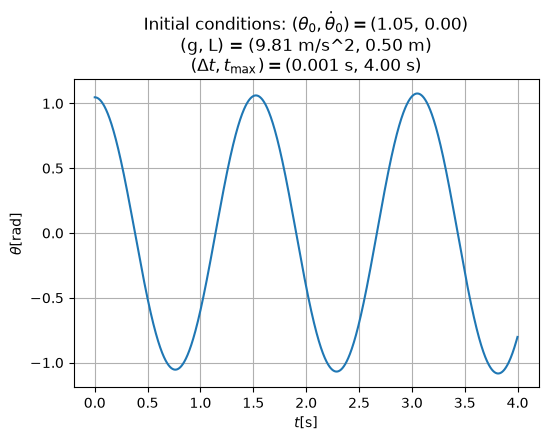

In [8]:
# Creating the figure 
import matplotlib.pyplot as plt 

fig, axs = plt.subplots(1, 1, figsize = (6, 4))

axs.plot(time, theta)
title = r"Initial conditions: $(\theta_0,\dot{\theta}_0)=$" + f"({init_conditions[0]:.2f}, {init_conditions[1]:.2f})\n" + f"(g, L) = ({g:.2f} m/s^2, {L:.2f} m)\n" + r"$(\Delta t, t_{\max})=$" + f"({delta_t:.2g} s, {t_max:.2f} s)"
axs.set(xlabel = r"$t$[s]", ylabel = r"$\theta$[rad]", title = title)
axs.grid()

*Question 2*: Créer une classe `Pendulum`. 

On va y aller étape par étape ensemble pour cette question.

Tout d'abord, créons une classe `Pendulum` dont la méthode `__init__` prendra comme paramètres les variables suivantes:
- `length`: la longueur de la tige du pendule 
- `thickness`: l'épaisseur de la tige du pendule. Vous pouvez donner une valeur par défaut de 5 à ce paramètre. 
- `radius`: le rayon du cercle représentant la masse du pendule. Vous pouvez donner une valeur par défaut de 0.05 à ce paramètre. 
- `color_rod`: la couleur de la tige. Vous pouvez donner une valeur par défaut de `"k"` à ce paramètre.
- `color_mass:` la couleur de la masse. Vous pouvez donner une valeur par défaut de `"red"` à ce paramètre. 

Vous pouvez instantier la classe et essayer d'afficher les différents attributs de celle-ci.

*Astuce: Vous pouvez afficher tous les attributs d'une classe dans un dictionnaire avec `__dict__`.*

In [42]:
class Pendulum():
    def __init__(self, length, thickness = 5, radius = 0.05, color_rod ="k", color_mass = "firebrick"):
        self.length = length 
        self.thickness = thickness
        self.radius = radius
        self.color_rod = color_rod
        self.color_mass = color_mass

pendulum = Pendulum(length = L)
print(pendulum.__dict__)

{'length': 1, 'thickness': 5, 'radius': 0.05, 'color_rod': 'k', 'color_mass': 'firebrick'}


Une fois que la méthode d'initialisation est bien programmée, on va s'intéresser à dessiner
notre pendule avec `matplotlib`.

Pour cela, nous coderons deux méthodes: 
- la première, `get_coords` qui prendra comme paramètre `theta` et qui renverra les coordonnées de la masse. Notez que les coordonnées de la masse sont données par 
$$
(x, y) = (L\sin(\theta), -L\cos(\theta))
$$

- la seconde, `draw` qui prendra trois paramètres (en plus du `self` de la classe):
    - `theta`
    - `fig` qui aura pour paramètre par défaut `None`.
    - `axs` qui aura pour paramètre par défaut `None`

Complétez ensuite le snippet de code suivant (qui devra être "à l'intérieur" de la fonction `draw`) pour dessiner le pendule,
```python
coords = ...

if axs is None:
    fig, axs = plt.subplots(1, 1, figsize = (4, 4))
self.circle = axs.add_patch(
    plt.Circle(..., ..., fc=self.color_mass, zorder=3)
)

(self.rod,) = axs.plot([0, coords[0]], [0, coords[1]], lw = ..., color = ...)
```

Pensez à utiliser les attributs qu'on a défini à la cellule précédente pour remplir le code.

Une fois la méthode `draw()` terminée, vous pouvez tester la classe et essayer de dessiner le pendule en faisant 
```python
pendule = Pendulum(length = L)
pendule.draw(theta = np.pi / 3)
```

In [10]:
class Pendulum:
    def __init__(self, length, thickness = 5, radius = 0.05, color_rod ="k", color_mass = "firebrick"):
        self.length = length 
        self.thickness = thickness
        self.radius = radius
        self.color_rod = color_rod
        self.color_mass = color_mass

    def get_coords(self, theta):
        coords = (self.length * np.sin(theta), -self.length * np.cos(theta))
        return coords
        
    def draw(self, theta, fig = None, axs = None):
        coords = self.get_coords(theta)

        if axs is None:
            fig, axs = plt.subplots(1, 1, figsize = (6, 4))
        self.circle = axs.add_patch(
            plt.Circle(coords, self.radius, fc=self.color_mass, zorder=3)
        )
        
        (self.rod,) = axs.plot([0, coords[0]], [0, coords[1]], lw = self.thickness, color = self.color_rod)


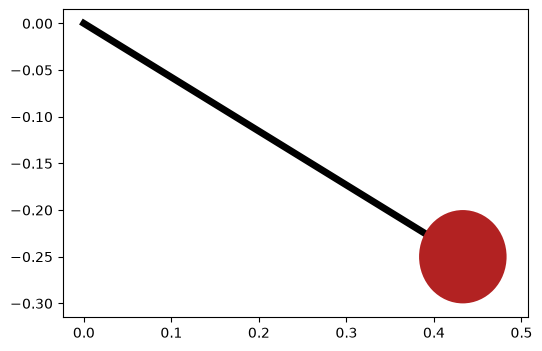

In [11]:
pendulum = Pendulum(length = L)
pendulum.draw(theta = np.pi / 3)

Pour terminer la classe et avoir tout ce dont on a besoin pour faire l'animation, il nous faut ajouter un moyen de mettre à jour l'emplacement des variables `self.circle` et `self.rod`.

La variable `self.circle` a une méthode `self.set_center((x, y))` qui permet de mettre à jour le centre du cercle. 

De la même façon, la variable `self.rod` peut être mis à jour via la méthode `self.set_data([0, x], [0, y]).

Ajoutez une dernière méthode `update` qui prendra comme paramètre le nouvel angle `theta` auquel dessiner le pendule. 

Vous pouvez tester la classe en dessinant le pendule à un angle $\theta_1$ avec la méthode `.draw()` et en mettant à jour l'angle du pendule 

_N'oubliez pas d'utiliser la méthode `get_coords` pour obtenir les coordonnées à partir de l'angle `theta`_

In [12]:
class Pendulum:
    def __init__(self, length, thickness = 3, radius = 0.05, color_rod ="k", color_mass = "firebrick"):
        self.length = length 
        self.thickness = thickness
        self.radius = radius
        self.color_rod = color_rod
        self.color_mass = color_mass

    def get_coords(self, theta):
        coords = (self.length * np.sin(theta), -self.length * np.cos(theta))
        return coords
        
    def draw(self, theta, fig = None, axs = None):
        coords = self.get_coords(theta)

        if axs is None:
            fig, axs = plt.subplots(1, 1, figsize = (4, 4))
        self.circle = axs.add_patch(
            plt.Circle(coords, self.radius, fc=self.color_mass, zorder=3)
        )
        
        (self.rod,) = axs.plot([0, coords[0]], [0, coords[1]], lw = self.thickness, color = self.color_rod)

    def update(self, theta):
        """
        To be used once the pendulum has been drawn once
        """
        new_coords = self.get_coords(theta)
        self.circle.set_center((new_coords))
        self.rod.set_data([0, new_coords[0]], [0, new_coords[1]])

On va maintenant passer à l'animation de notre simulation de pendule. On utilisera 
la fonction `FuncAnimation` de `matplotlib.animation` pour cela. 
Cette partie, je la fais moi-même pour que ça vous donne un exemple de comment faire une animation en Python.

Par contre, à la prochaine série d'exercices, il y aura un exercice où vous devrez animer le problème à deux corps je vous conseille donc de bien comprendre le code ci-dessous. 

In [13]:
pendulum = Pendulum(length = L, radius = 0.05)

In [ ]:
# Importing function for animation
from matplotlib.animation import FuncAnimation 

# Importing function for displaying the animation
from IPython.display import HTML, display


fig, axs = plt.subplots(1, 1, figsize = (4, 4))
factor = 1.2

text = axs.annotate(f"t={time[0]:.2f}", xy = (0.1, 0.8), xycoords = "axes fraction")
axs.set(xlim = [-factor * L, factor * L], ylim = [-factor * L, factor * L])

pendulum.draw(theta = init_conditions[0], fig = fig, axs = axs)

def animate(frame):
    "Update animation"
    text.set_text(f"t={time[frame]:.2f}")
    pendulum.update(angle[frame])

# Choosing the number of frames per second in the animation (e.g. 60)
fps = 60

# Subsampling steps of simulation to simulate 60 frames per second
num_frames_per_sim_step = fps * delta_t
num_sim_step_per_frame = round(1 / (num_frames_per_sim_step))
frames = range(0, len(theta), num_sim_step_per_frame)
interval = 1000 / fps # interval in ms 

ani = FuncAnimation(fig, animate, frames = frames, interval = interval, repeat = True)
plt.close(fig)  # Avoid displaying a static figure

# Displaying the animation in a notebook 
display(HTML(ani.to_jshtml()))

Finalement, l'animation du pendule peut être sauvegardée sous la forme d'un GIF comme suit.

In [35]:
from matplotlib.animation import PillowWriter

writer = PillowWriter(fps = fps)
ani.save("pendulum.gif", writer = writer)

Cet exercice était inspiré de l'exemple sur l'animation d'un pendule de la [documentation scipy](https://scipython.com/books/book2/chapter-7-matplotlib/problems/animating-a-pendulum/) où on a utilisé une classe pour dessiner le pendule.

##### Exercice 2: Mixture de distributions gaussiennes

Dans cet exercice, on va utiliser une classe pour créer une mixture de gaussiennes et l'afficher sur une figure. La densité de probabilité est une fonction de $x$ qui peut être écrite comme
\begin{equation}
    p(x) = \frac{1}{\sum_{i=1}^{N} w_i}\sum_{i=1}^{N}w_i\mathcal{N}(x\mid \mu_i, \sigma^2_i)
\end{equation}

_Question 1: Initialisation de la classe_

Commencez par coder la méthode `__init__` de la classe. La méthode `__init__` prendra comme paramètres:
- `weights`: paramètre auquel on donnera un tableau numpy contenant les valeurs des variables $(w_1, w_2)$
- `means`: paramètre auquel on donnera un tableau numpy contenant les valeurs des variables $(\mu_1, \mu_2)$ 
- `stds`: paramètre auquel on donnera un tableau numpy contenant les valeurs des variables $(\sigma_1, \sigma_2)$

Associez un attribut du même nom à chacun de ces paramètres. Testez votre classe en l'initialisant. 

In [43]:
class MixtureGaussian:
    def __init__(self, weights, means, stds):
        self.weights = weights
        self.means = means
        self.stds = stds

weights = np.array([2, 1])
means = np.array([-1, 1])
stds = np.array([1, 1])
mixture_gaussian = MixtureGaussian(weights, means, stds)

_Question 2: Méthode pour la densité de probabilité de la classe_

Créez une méthode `gaussian_pdf(x, mean, std)` à la classe `MixtureGaussian` pour calculer la densité de probabilité d'une fonction Gaussienne avec moyenne $\mu$ et déviation standard $\sigma$. La fonction peut être écrite comme suit,  
$$
\mathcal{N}(x\mid \mu, \sigma^2) = \frac{1}{\sqrt{2\pi \sigma^2}} \exp\left(-\frac{(x - \mu)^2}{2\sigma^2}\right)
$$

Tracez la densité en fonction de $x\in[-5, 5]$ avec $\mu=0$ et $\sigma=1$. Annotez la figure de manière appropriée. 

[Text(0.5, 0, '$x$'),
 Text(0, 0.5, 'Density $p(x)$'),
 Text(0.5, 1.0, 'Distribution Gaussienne')]

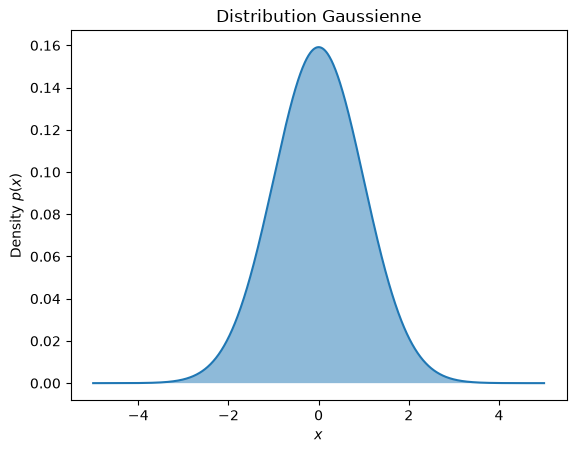

In [ ]:
class MixtureGaussian:
    def __init__(self, weights, means, stds):
        self.weights = weights
        self.means = means
        self.stds = stds

    def gaussian_pdf(self, x, mean, std):
        return np.exp( - 0.5 * (x - mean) ** 2 / std ** 2) / (2 * np.pi * std ** 2)


mixture_gaussian = MixtureGaussian(weights = weights, means = means, stds = stds)
x = np.linspace(-5, 5, 1000)


plt.plot(x, mixture_gaussian.gaussian_pdf(x = x, mean = 0, std = 1))
plt.fill_between(x, mixture_gaussian.gaussian_pdf(x = x, mean = 0, std = 1), alpha = 0.5)
plt.gca().set(xlabel = r"$x$", ylabel = r"Density $p(x)$", title = "Distribution Gaussienne")

_Question 3: Méthode pour calculer la densité de la mixture de gaussiennes_

Créez une méthode pour calculer la densité de la mixture de gaussiennes en utilisant une boucle `for`. Je vous rappelle la formule de la densité,
$$
p(x)=\frac{1}{\sum_{i=1}^{N} w_i} \sum_{i=1}^{N} w_i\mathcal{N}(x\mid \mu_i, \sigma^2_i)
$$
Pensez à réutiliser la méthode `gaussian_pdf` pour calculer $\mathcal{N}(x\mid \mu_i, \sigma^2_i)$.

Testez si votre fonction est bien implémenté avec le snippet de code suivant 
```python
from scipy.integrate import simpson

weights = np.array([1., 2.])
stds = np.array([1., 1.])
means = np.array([-1., 1.])
MixtureGaussian()
x = np.linspace(-100, 100, 10_000)
y = mixture_gaussian.pdf(x)
```
Il permet de calculer l'intégrale de la densité de la mixture de gaussiennes. Celle-ci devrait être normalisée et égale à 1, i.e.
$$
\int_{-\infty}^{\infty} p(x)dx = 1.
$$

(ceci correspond à sommer sur la probabilité de tous les événements possibles.)

In [ ]:
class MixtureGaussian:
    def __init__(self, weights, means, stds):
        self.weights = weights
        self.means = means
        self.stds = stds

    def gaussian_pdf(self, x, mean, std):
        return np.exp( - 0.5 * (x - mean) ** 2 / std ** 2) / (2 * np.pi * std ** 2)

    def pdf(self, x):
        density = 0
        for i in range(len(self.weights)):
            comp_pdf = self.gaussian_pdf(x, mean = self.means[i], stds = self.stds[i])
            density += self.weights[i] * comp_pdf / (self.weights.sum())
        return density

##### Exercice 3: Classe générale pour mouvement d'une particule dans un champ vectoriel uniforme. 

